# Brazil Section 301 — Tariff Impact and Exemption Coverage

Analyzes the July 22, 2026 Section 301 action on Brazil (USTR Notice of Action,
Jul 15, 2026): a 25% additional duty on all goods of Brazil, with exemptions set
out in U.S. note 50 to subchapter III of chapter 99.

**Generates:** `figures/brazil-301-*.pdf/png`

**Run after** `make-tariff-by-country-by-time.ipynb` — reads
[country-by-time.csv](country-by-time.csv) and imports the tariff engine directly
from that notebook, so there is no duplicated copy of the masks or the registry.

In [1]:
import json
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
figfile = "./figures/"
os.makedirs(figfile, exist_ok=True)

plt.rcParams.update({
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.linewidth':    2,
    'axes.labelweight':  'bold',
    'axes.titleweight':  'bold',
    'axes.titlesize':    18,
    'axes.labelsize':    16,
    'xtick.labelsize':   12,
    'ytick.labelsize':   12,
    'legend.frameon':    False,
    'legend.fontsize':   12,
    'grid.alpha':        0.3,
    'grid.linestyle':    '--',
    'savefig.bbox':      'tight',
})

PALETTE = {
    'aggregate':  'black',
    'primary':    'darkblue',
    'secondary':  '#8B0000',
    'tertiary':   'darkgreen',
    'rank1':      '#2E5090',
    'rank2':      '#4A90E2',
    'rank3':      '#7CB9E8',
}

BRAZIL = "3510"

# Import-weight year. Set separately here because it is defined in the main
# notebook's panel-construction cell, which runs after the engine cells loaded
# below — keep it in sync with WEIGHT_YEAR there.
WEIGHT_YEAR = 2024

## Load the tariff engine

Rather than keeping a second copy of the masks and action registry, execute the
main notebook's code cells in order and stop once `tariff_imports` is defined.
This runs the data loaders, product lists, masks, apply functions, and the
registry — but not the panel-construction loop that follows.

In [3]:
_nb = json.load(io.open('make-tariff-by-country-by-time.ipynb', encoding='utf-8'))

for _cell in _nb['cells']:
    if _cell['cell_type'] != 'code':
        continue
    _src = ''.join(_cell['source'])
    exec(compile(_src, 'tariff-engine', 'exec'))
    if 'def tariff_imports' in _src:
        break

print(f"engine loaded — {len(TARIFF_ACTIONS)} tariff actions")

engine loaded — 89 tariff actions


## Section 1 — Brazil's effective tariff over time

`country-by-time.csv` holds the import-weighted effective rate for each
country-date. Rates are the *policy-added* duty and exclude the pre-existing MFN
baseline, so the national average is shown net of the 2.3pp baseline that the
main notebook adds back for the published series.

In [4]:
panel = pd.read_csv('country-by-time.csv', parse_dates=['date'])

brazil = (panel[panel['country_name'] == 'BRAZIL']
          .set_index('date')['effective tariff']
          .sort_index())

national = (pd.read_csv('daily-tariff-latest-data.csv', parse_dates=['date'])
            .set_index('date')['import_weighted_avg_tariff'] - 2.3)

# Forward-fill Brazil from policy dates to a daily series.
days = pd.date_range('2025-01-01', '2026-12-31', freq='D')
brazil_daily = brazil.reindex(days.union(brazil.index)).ffill().fillna(0.0).reindex(days)
national_daily = national.reindex(days).ffill()

brazil_daily.tail()

2026-12-27    17.826124
2026-12-28    17.826124
2026-12-29    17.826124
2026-12-30    17.826124
2026-12-31    17.826124
Freq: D, Name: effective tariff, dtype: float64

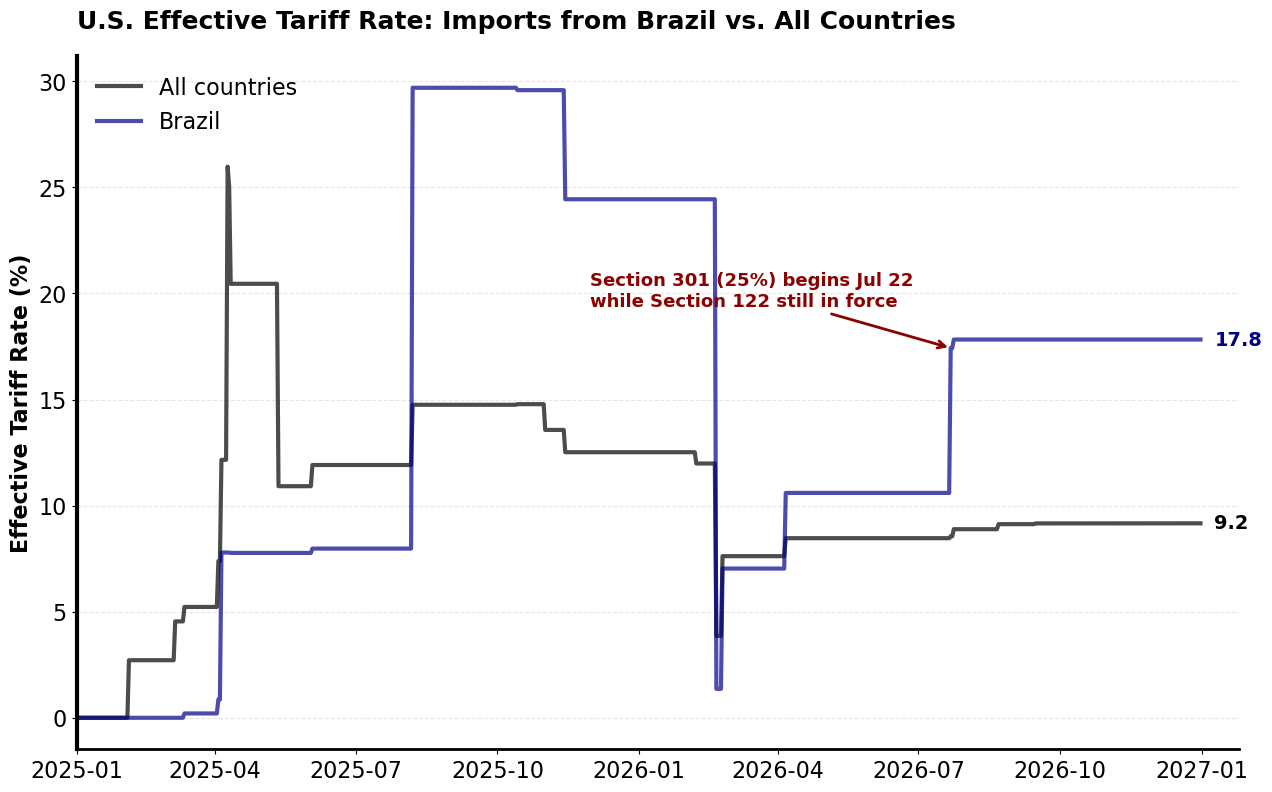

In [5]:
fig, ax = plt.subplots(figsize=(15, 9))

ax.plot(national_daily.index, national_daily.values,
        color=PALETTE['aggregate'], linewidth=3, alpha=0.7,
        label='All countries')
ax.plot(brazil_daily.index, brazil_daily.values,
        color=PALETTE['primary'], linewidth=3, alpha=0.7,
        label='Brazil')

peak = brazil_daily.loc['2026-07-22']
ax.annotate('Section 301 (25%) begins Jul 22\nwhile Section 122 still in force',
            xy=(pd.Timestamp('2026-07-22'), peak),
            xytext=(-260, 30), textcoords='offset points',
            fontsize=13, fontweight='bold', color=PALETTE['secondary'],
            arrowprops=dict(arrowstyle='->', color=PALETTE['secondary'], linewidth=2))

for series, color in [(brazil_daily, PALETTE['primary']),
                      (national_daily, PALETTE['aggregate'])]:
    ax.annotate(f'{series.iloc[-1]:.1f}',
                xy=(series.index[-1], series.iloc[-1]),
                xytext=(10, 0), textcoords='offset points',
                fontsize=14, fontweight='bold', color=color, va='center')

ax.set_ylabel('Effective Tariff Rate (%)', fontsize=16, fontweight='bold')
ax.set_title('U.S. Effective Tariff Rate: Imports from Brazil vs. All Countries',
             fontsize=18, fontweight='bold', pad=20, loc='left')
ax.set_xlim([pd.Timestamp('2025-01-01'), pd.Timestamp('2027-01-25')])
ax.spines['left'].set_linewidth(3)
ax.spines['bottom'].set_linewidth(2)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.tick_params(axis='both', labelsize=16)
ax.legend(fontsize=16, frameon=False, loc='upper left')

plt.savefig(figfile + 'brazil-301-timeline.png', bbox_inches='tight')
plt.savefig(figfile + 'brazil-301-timeline.pdf', bbox_inches='tight')
plt.show()

## Section 2 — Where the 25% lands

Every HS10 line of 2024 U.S. imports from Brazil is assigned to exactly one
channel. Exemption categories overlap in the source notice (209 codes appear on
both an exemption list and a Section 232 list), so codes are assigned in the
order the notice presents them, first match wins.

In [6]:
imports = load_imports(BRAZIL, year=WEIGHT_YEAR)

exempt_codes = pd.read_csv('./tariff-lists/brazil-301-exemptions.csv',
                           dtype={'HTSUS': str})

def _cat_mask(df, category):
    codes = set(exempt_codes.loc[exempt_codes['category'] == category, 'HTSUS'])
    return df['HS8'].isin(codes) | df['HS10'].isin(codes)

# Section 232 goods are exempt under (a)(vi), except those removed from 232
# scope by the Apr 6, 2026 metals Annex II.
mask_232 = _mask_all_232(imports) & ~_mask_annex_II_removed(imports)

CHANNELS = [
    ('Listed subheadings\n(a)(ii)-(iii)', _cat_mask(imports, 'flat') | _cat_mask(imports, 'named'), PALETTE['rank1']),
    ('Section 232 sectors\n(a)(vi)',       mask_232,                                                PALETTE['rank2']),
    ('Civil aircraft\n(a)(iv)',            _cat_mask(imports, 'aircraft'),                          PALETTE['rank3']),
    ('Pharmaceutical use\n(a)(v)',         _cat_mask(imports, 'pharma'),                            PALETTE['tertiary']),
]

channel = pd.Series('Pays 25%', index=imports.index)
assigned = pd.Series(False, index=imports.index)
for label, mask, _ in CHANNELS:
    fresh = mask & ~assigned
    channel[fresh] = label
    assigned |= mask

coverage = (100 * imports.groupby(channel)['share'].sum())
order = ['Pays 25%'] + [c[0] for c in CHANNELS]
coverage = coverage.reindex(order).fillna(0.0)
coverage.round(2)

Pays 25%                             27.31
Listed subheadings\n(a)(ii)-(iii)    47.18
Section 232 sectors\n(a)(vi)         17.91
Civil aircraft\n(a)(iv)               6.75
Pharmaceutical use\n(a)(v)            0.86
Name: share, dtype: float64

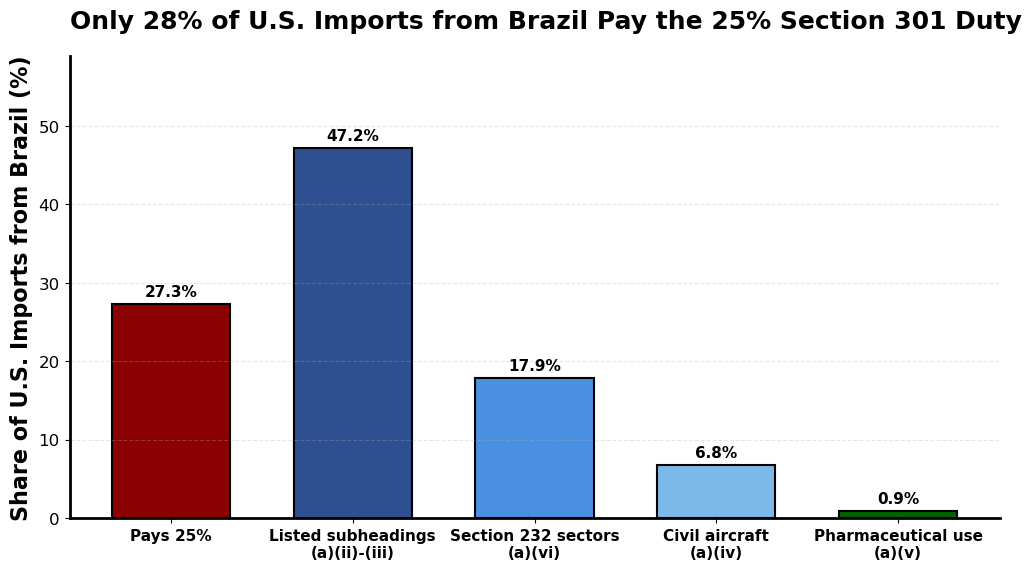

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))

colors = [PALETTE['secondary']] + [c[2] for c in CHANNELS]
bars = ax.bar(range(len(coverage)), coverage.values, 0.65,
              color=colors, edgecolor='black', linewidth=1.5)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.6, f'{h:.1f}%',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_xticks(range(len(coverage)))
ax.set_xticklabels(coverage.index, fontsize=11)
for label in ax.get_xticklabels():
    label.set_fontweight('bold')

ax.set_ylabel('Share of U.S. Imports from Brazil (%)', fontsize=16, fontweight='bold')
ax.set_title('Only 28% of U.S. Imports from Brazil Pay the 25% Section 301 Duty',
             fontsize=18, fontweight='bold', pad=20, loc='left')
ax.set_ylim([0, coverage.max() * 1.25])
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.savefig(figfile + 'brazil-301-exemption-anatomy.png', bbox_inches='tight')
plt.savefig(figfile + 'brazil-301-exemption-anatomy.pdf', bbox_inches='tight')
plt.show()

## Section 3 — Which sectors bear the duty

Top 10 HS2 chapters by 2024 import value. The full bar is total imports; the
hatched portion is the part subject to the 25% duty.

Two bars overstate the hatched share because of known modeling gaps: **Ch. 98**
should be almost entirely exempt under note 50(a)(i) (see Section 5), and **Wood**
should be largely exempt under (a)(vi) but the timber Section 232 action
(Proc 10976) is not modeled.

In [8]:
imports['HS2'] = imports['HS10'].str[:2]
imports['covered'] = (channel == 'Pays 25%')

HS2_NAMES = {
    '27': 'Mineral fuels',      '72': 'Iron & steel',       '84': 'Machinery',
    '98': 'Ch. 98 special',     '88': 'Aircraft',           '09': 'Coffee & spices',
    '47': 'Wood pulp',          '44': 'Wood',               '85': 'Electrical mach.',
    '20': 'Prepared fruit/veg', '87': 'Vehicles',           '02': 'Meat',
    '76': 'Aluminum',           '64': 'Footwear',           '73': 'Iron/steel articles',
}

by_hs2 = (imports.groupby('HS2')
          .apply(lambda x: pd.Series({
              'total':   x['imports'].sum() / 1e9,
              'covered': x.loc[x['covered'], 'imports'].sum() / 1e9,
          }), include_groups=False)
          .sort_values('total', ascending=False)
          .head(10))

by_hs2['label'] = [f"{HS2_NAMES.get(h, h)}\n({h})" for h in by_hs2.index]
by_hs2.round(2)

,total,covered,label
HS2,,,
27,8.66,0.00,Mineral fuels\n(27)
72,4.77,0.06,Iron & steel\n(72)
84,2.82,0.62,Machinery\n(84)
98,2.65,2.43,Ch. 98 special\n(98)
88,2.04,0.00,Aircraft\n(88)
09,2.00,0.00,Coffee & spices\n(09)
47,1.77,0.21,Wood pulp\n(47)
44,1.55,1.29,Wood\n(44)
85,1.37,0.15,Electrical mach.\n(85)


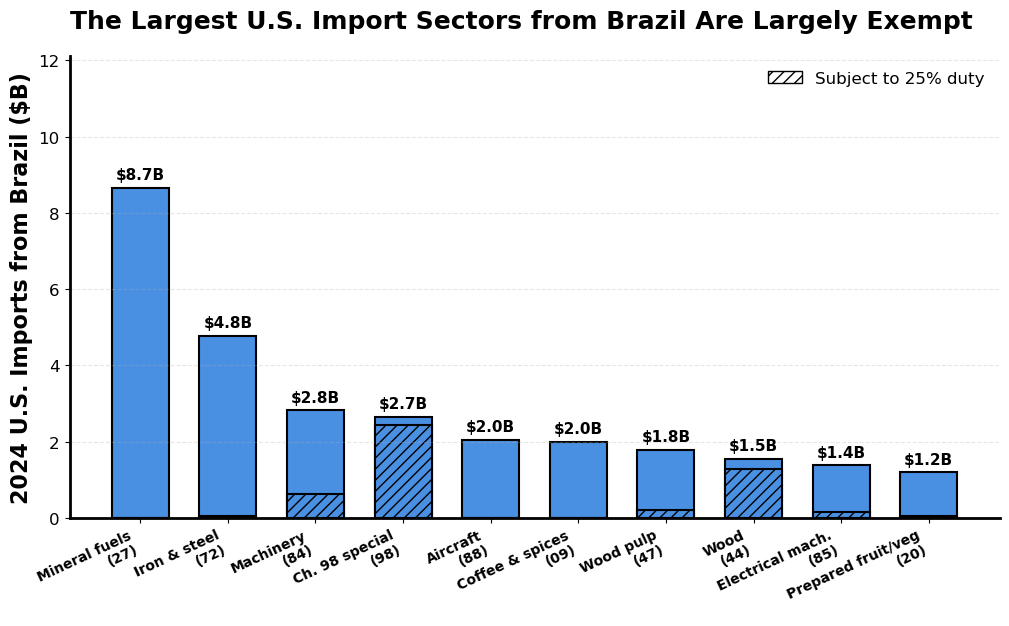

In [9]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(by_hs2))

ax.bar(x, by_hs2['total'], 0.65,
       color=PALETTE['rank2'], edgecolor='black', linewidth=1.5)
ax.bar(x, by_hs2['covered'], 0.65,
       color=PALETTE['rank2'], edgecolor='black', linewidth=1.5, hatch='///')

for xi, (total, covered) in enumerate(zip(by_hs2['total'], by_hs2['covered'])):
    ax.text(xi, total + 0.15, f'${total:.1f}B',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(by_hs2['label'], fontsize=10, rotation=25, ha='right')
for label in ax.get_xticklabels():
    label.set_fontweight('bold')

ax.set_ylabel('2024 U.S. Imports from Brazil ($B)', fontsize=16, fontweight='bold')
ax.set_title("The Largest U.S. Import Sectors from Brazil Are Largely Exempt",
             fontsize=18, fontweight='bold', pad=20, loc='left')
ax.set_ylim([0, by_hs2['total'].max() * 1.40])
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.legend(handles=[Patch(facecolor='white', edgecolor='black', hatch='///',
                         label='Subject to 25% duty')],
          fontsize=12, frameon=False, loc='upper right')

plt.savefig(figfile + 'brazil-301-by-sector.png', bbox_inches='tight')
plt.savefig(figfile + 'brazil-301-by-sector.pdf', bbox_inches='tight')
plt.show()

## Section 4 — What fraction pays any tariff?

Section 2 asked how much of the basket escapes the *Section 301* duty. The
broader question is how much pays **any** tariff from the recent actions —
Section 301, the surviving Section 232 sectors, and (before it lapses) the
Section 122 surcharge.

Three dates are compared:

- **Apr 6, 2026** — Section 122 surcharge in force, no 301
- **Jul 22, 2026** — both live, the three-day overlap
- **Jul 25, 2026** — 122 lapsed, 301 alone

In [10]:
INCIDENCE_DATES = ['2026-04-06', '2026-07-22', '2026-07-25']

incidence = {}
for date_str in INCIDENCE_DATES:
    result = tariff_imports(load_imports(BRAZIL, year=WEIGHT_YEAR), BRAZIL, 0.0,
                            pd.to_datetime(date_str))
    by_rate = result.groupby('tariff').agg(
        share=('share', 'sum'),
        value=('imports', 'sum'),
    )
    by_rate['share'] *= 100
    by_rate['value'] /= 1e9
    incidence[date_str] = by_rate

for date_str, by_rate in incidence.items():
    paying = by_rate[by_rate.index > 0]
    print(f"--- {date_str}")
    for rate, row in by_rate.iterrows():
        print(f"    {rate:5.1f}%   {row['share']:5.2f}% of imports   ${row['value']:5.2f}B")
    print(f"    pays any tariff: {paying['share'].sum():.1f}%  (${paying['value'].sum():.1f}B)")
    print()

--- 2026-04-06
      0.0%   39.98% of imports   $17.09B
     10.0%   42.38% of imports   $18.12B
     15.0%    1.04% of imports   $ 0.44B
     25.0%    8.40% of imports   $ 3.59B
     50.0%    8.21% of imports   $ 3.51B
    pays any tariff: 60.0%  ($25.7B)

--- 2026-07-22
      0.0%   39.05% of imports   $16.69B
     10.0%   15.99% of imports   $ 6.84B
     15.0%    1.04% of imports   $ 0.44B
     25.0%    9.32% of imports   $ 3.98B
     35.0%   26.38% of imports   $11.28B
     50.0%    8.21% of imports   $ 3.51B
    pays any tariff: 60.9%  ($26.1B)

--- 2026-07-25
      0.0%   44.29% of imports   $18.93B
     10.0%    0.30% of imports   $ 0.13B
     12.5%   10.46% of imports   $ 4.47B
     15.0%    1.04% of imports   $ 0.44B
     25.0%    9.29% of imports   $ 3.97B
     37.5%   26.41% of imports   $11.29B
     50.0%    8.21% of imports   $ 3.51B
    pays any tariff: 55.7%  ($23.8B)



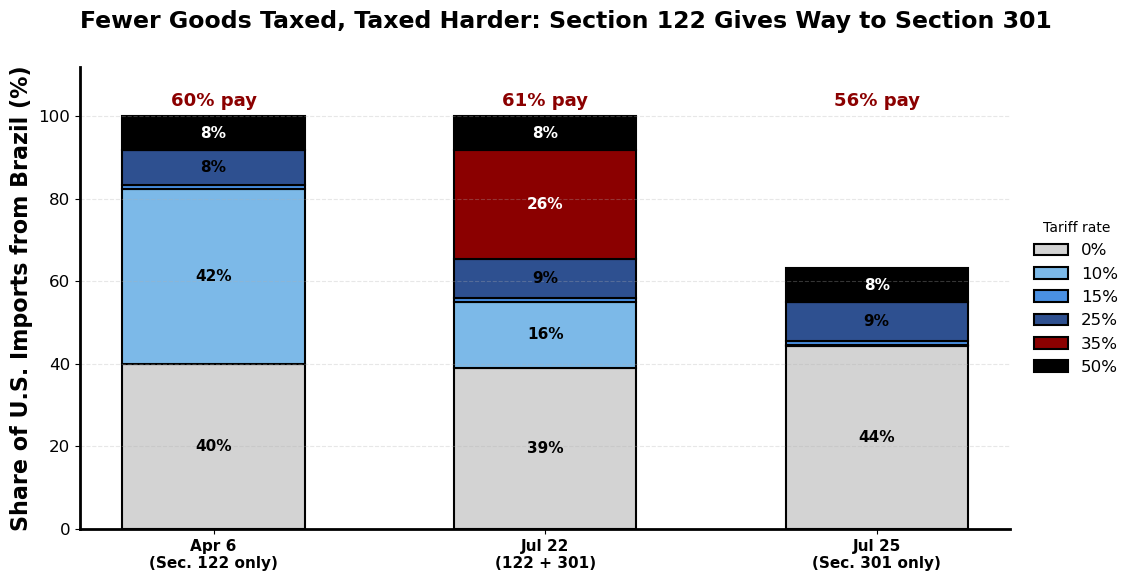

In [11]:
fig, ax = plt.subplots(figsize=(12, 6))

# Stack each date's imports by the rate they face.
RATE_COLORS = {
    0.0:  '#D3D3D3',
    10.0: PALETTE['rank3'],
    15.0: PALETTE['rank2'],
    25.0: PALETTE['rank1'],
    35.0: PALETTE['secondary'],
    50.0: 'black',
}
LABELS = {'2026-04-06': 'Apr 6\n(Sec. 122 only)',
          '2026-07-22': 'Jul 22\n(122 + 301)',
          '2026-07-25': 'Jul 25\n(Sec. 301 only)'}

x = np.arange(len(INCIDENCE_DATES))
bottom = np.zeros(len(INCIDENCE_DATES))

for rate in sorted(RATE_COLORS):
    heights = np.array([incidence[d]['share'].get(rate, 0.0) for d in INCIDENCE_DATES])
    if heights.sum() == 0:
        continue
    ax.bar(x, heights, 0.55, bottom=bottom,
           color=RATE_COLORS[rate], edgecolor='black', linewidth=1.5,
           label=f'{rate:.0f}%')
    for xi, (h, b) in enumerate(zip(heights, bottom)):
        if h > 3:
            ax.text(xi, b + h / 2, f'{h:.0f}%', ha='center', va='center',
                    fontsize=11, fontweight='bold',
                    color='white' if rate >= 35 else 'black')
    bottom += heights

for xi, date_str in enumerate(INCIDENCE_DATES):
    exempt = incidence[date_str]['share'].get(0.0, 0.0)
    ax.text(xi, 101.5, f'{100 - exempt:.0f}% pay', ha='center', va='bottom',
            fontsize=13, fontweight='bold', color=PALETTE['secondary'])

ax.set_xticks(x)
ax.set_xticklabels([LABELS[d] for d in INCIDENCE_DATES], fontsize=11)
for label in ax.get_xticklabels():
    label.set_fontweight('bold')

ax.set_ylabel('Share of U.S. Imports from Brazil (%)', fontsize=16, fontweight='bold')
ax.set_title('Fewer Goods Taxed, Taxed Harder: Section 122 Gives Way to Section 301',
             fontsize=17, fontweight='bold', pad=28, loc='left')
ax.set_ylim([0, 112])
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.legend(fontsize=12, frameon=False, loc='center left',
          bbox_to_anchor=(1.01, 0.5), title='Tariff rate')

plt.savefig(figfile + 'brazil-301-incidence.png', bbox_inches='tight')
plt.savefig(figfile + 'brazil-301-incidence.pdf', bbox_inches='tight')
plt.show()

Coverage **falls** when Section 122 gives way to Section 301 — from 60% of
imports paying something to 45% — while the rate on covered goods rises sharply.
The Section 122 surcharge was broad and shallow (10% on nearly half the basket);
the 301 duty is narrower and four times as steep. Fewer goods, taxed harder.

The Jul 22–24 overlap is the peak: 61% of imports pay something, with $11.4B
sitting at the stacked 35% rate.

## Section 5 — Summary and known biases

Effective rates on the key dates, and the direction of each modeling
approximation. See the README for the full limitations discussion.

In [12]:
summary = []
for date_str in ['2026-04-06', '2026-07-22', '2026-07-25']:
    result = tariff_imports(load_imports(BRAZIL, year=WEIGHT_YEAR), BRAZIL, 0.0,
                            pd.to_datetime(date_str))
    summary.append({
        'date': date_str,
        'effective rate': (result['tariff'] * result['share']).sum(),
    })

summary = pd.DataFrame(summary).set_index('date').round(2)
print(summary.to_string())
print()
print(f"Total 2024 U.S. imports from Brazil: ${imports['imports'].sum()/1e9:.1f}B")
print(f"Exempt from Section 301:            {100 - coverage['Pays 25%']:.1f}% of imports")

            effective rate
date                      
2026-04-06           10.60
2026-07-22           17.43
2026-07-25           17.83

Total 2024 U.S. imports from Brazil: $42.7B
Exempt from Section 301:            72.7% of imports


### Chapter 98 — an unmodeled exemption

U.S. note 50(a)(i) states the additional duty "shall not apply to goods for which
entry is properly claimed under a provision of chapter 98", except goods entered
under 9802.00.40, 9802.00.50, 9802.00.60 or 9802.00.80 (which pay on the value of
repairs, alterations, processing, or foreign assembly).

Chapter 98 is not a product classification — it covers U.S. goods returned,
temporary imports, and similar — and the tariff engine does not model it. For
Brazil this is material: chapter 98 is the fourth-largest import chapter.

In [13]:
result = tariff_imports(load_imports(BRAZIL, year=WEIGHT_YEAR), BRAZIL, 0.0,
                        pd.to_datetime('2026-07-25'))

ch98 = result['HS10'].str[:2] == '98'
carve_back = result['HS10'].str[:6].isin(['980240', '980250', '980260', '980280'])

as_modeled = (result['tariff'] * result['share']).sum()

adjusted = result.copy()
adjusted.loc[ch98 & ~carve_back, 'tariff'] = 0.0
if_exempt = (adjusted['tariff'] * adjusted['share']).sum()

print(f"Ch. 98 share of U.S. imports from Brazil : {100*result.loc[ch98, 'share'].sum():.2f}%")
print(f"  in the 9802 carve-back headings         : {100*result.loc[ch98 & carve_back, 'share'].sum():.2f}%")
print()
print(f"Effective rate as modeled                : {as_modeled:.2f}%")
print(f"Effective rate if Ch. 98 exempted        : {if_exempt:.2f}%")
print(f"  overstatement                          : {as_modeled - if_exempt:.2f} pp")

Ch. 98 share of U.S. imports from Brazil : 6.20%
  in the 9802 carve-back headings         : 0.00%

Effective rate as modeled                : 17.83%
Effective rate if Ch. 98 exempted        : 15.63%
  overstatement                          : 2.19 pp


### Direction of each approximation

| Approximation | Effect on Brazil's rate |
|---|---|
| Chapter 98 exemption not modeled | **Overstates** by ~1.4pp |
| Timber, MHD vehicles, semiconductors, patented pharma not modeled as Section 232, so they lose the (a)(vi) carve-out | Overstates |
| Aircraft (general note 6) and pharma end-use exemptions applied flat to every listed code | Understates |
| In-transit relief (loaded before Jul 22, entered before Jul 29) ignored | Overstates for Jul 22–28 only |
| All start and end dates modeled literally, so the Section 122 surcharge and the 301 duty stack for Jul 22–24 | Produces the three-day spike |